<a href="https://colab.research.google.com/github/bauhaushm/TP-Delito_en_AMBA/blob/SantiagoPeralta/TP_Delito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Grupal - Laboratorio de Métodos Cuantitativos
**Universidad de Buenos Aires - Facultad de Ciencias Económicas**  
**Tecnicatura Universitaria en Gestión y Análisis de Datos**  
**Segundo Cuatrimestre 2026**

---

### Integrantes del Grupo:
* **Chietino Luna, Micaela** - Registro: 921785 - Usuario GitHub: `@mchietino`
* **Iandoli, Franco** - Registro: 921507 - Usuario GitHub: `@Franco-Iandoli`
* **Ortiz, Naiara** - Registro: 921844 - Usuario GitHub: `@naiaraortizrodriguez`
* **Peralta, Santiago** - Registro: 921431 - Usuario GitHub: `@SantiagoNPeralta`
* **Turrillo, Bruno** - Registro: 921414 - Usuario GitHub: `@bauhaushm`

---

## 1. Introducción y Pregunta de Investigación

Nuestro grupo se focalizará en la temática del delito y su relación con aspectos sociales que pueden influir en él.

**Pregunta de investigación:**
> *¿Cómo se articulan la frecuencia y el tipo de hecho delictivo con la estructura socioeconómica y comercial de CABA y del Conurbano bonaerense?*

Incialmente usamos como fuente principal el Sistema Nacional de Información Criminal (Snic). El URL https://www.argentina.gob.ar/seguridad/estadisticascriminales/bases-de-datos contiene diferentes datasets del cual elegimos "SNIC - Departamentos. Anual. Años 2000-2025".

In [99]:
#importamos las librerías que vamos a utilizar
import pandas as pd #para manipular los archivos
import matplotlib.pyplot as plt #para hacer gráficos
import seaborn as sb #para hacer gráficos
import numpy as np #para realizar operaciones matemáticas
import colorsys #para definir los colores de las barras (convierte colores de HLS a RGB)

Le pedimos a Pandas que nos haga un filtrado de filas y columnas del dataset. Acotamos el rango a la franja de años 2017-2025 (últimos 9 años) y reducimos la información a las columnas: "Año", "Provincia", "Departamentos", "Tipo de delito", "Cantidad de Hechos" y "Tasa de delito (cada 100.000 habitantes)". Nombramos al nuevo dataset obtenido.

In [100]:
# 1. Cargar únicamente las columnas A, C, E, G, H, M (índices 0, 2, 4, 6, 7, 12)
columnas = [0, 2, 4, 6, 7, 9, 10, 11, 12]
url = "https://raw.githubusercontent.com/bauhaushm/TP-Delito_en_AMBA/SantiagoPeralta/DF/snic_completo.zip"
df = pd.read_csv(url, usecols=columnas, low_memory=False)

# 2. Filtrar únicamente para los años entre 2017 y 2025
df_delito = df[(df['anio'] >= 2017) & (df['anio'] <= 2025)]

# 3. Verificar el resultado
print(f"El dataset filtrado contiene {len(df_delito)} filas y {len(df_delito.columns)} columnas.")
print("Años incluidos:", sorted(df_delito['anio'].unique()))

# 4. Guardar el nuevo dataset resultante
df_delito.to_excel('snic_2017_2025_delito.xlsx', index=False)
df_delito.to_csv('snic_2017_2025_delito.csv', index=False)

El dataset filtrado contiene 288832 filas y 9 columnas.
Años incluidos: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


Visualizamos el nuevo dataframe generado

In [101]:
df_delito

,anio,provincia_nombre,departamento_nombre,codigo_delito_snic_nombre,cantidad_hechos,cantidad_victimas_masc,cantidad_victimas_fem,cantidad_victimas_sd,tasa_hechos
8448,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Homicidios dolosos,25,21.0,4.0,0.0,9.870850
8449,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Abusos sexuales con acceso carnal (violaciones),14,0.0,14.0,2.0,5.527676
8450,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Otros delitos contra la integridad sexual,190,22.0,171.0,16.0,75.018458
8451,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Delitos contra el estado civil,0,NaN,NaN,NaN,0.000000
8452,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Amenazas,1074,NaN,NaN,NaN,424.051707
...,...,...,...,...,...,...,...,...,...
569875,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Lesiones dolosas,341,164.0,177.0,0.0,433.627081
569876,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Lesiones culposas en Accidentes Viales,70,51.0,36.0,0.0,89.014357
569877,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Lesiones culposas por otros hechos,1,0.0,1.0,0.0,1.271634
569878,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Otros delitos contra las personas,879,344.0,535.0,0.0,1117.765994


Contamos el total general de valores nulos (NaN) de todo el dataset:

In [102]:
df_delito.isna().sum()

,0
anio,0
provincia_nombre,0
departamento_nombre,122
codigo_delito_snic_nombre,0
cantidad_hechos,0
cantidad_victimas_masc,209280
cantidad_victimas_fem,209280
cantidad_victimas_sd,209280
tasa_hechos,12805


Antes de modificar los datos nulos (Nan), evaluamos la magnitud del problema verificando la cantidad por columna y la proporción en relación al total de datos de esa columna

In [103]:
# Cantidad de nulos por columna
df_delito.isnull().sum()

# Porcentaje de nulos por columna
(df_delito.isnull().sum() / len(df)) * 100

,0
anio,0.000000
provincia_nombre,0.000000
departamento_nombre,0.021408
codigo_delito_snic_nombre,0.000000
cantidad_hechos,0.000000
cantidad_victimas_masc,36.723521
cantidad_victimas_fem,36.723521
cantidad_victimas_sd,36.723521
tasa_hechos,2.246964


Se detectó un 0,02% de valores nulos en departamento_nombre, correspondientes a hechos reportados sin ubicación subprovincial específica, los cuales fueron imputados bajo la etiqueta 'Departamento sin determinar' para conservar la totalidad de los delitos registrados. Asimismo, el 2,25% de nulos en tasa_hechos se mantuvo sin imputar debido a la imposibilidad metodológica de calcular tasas poblacionales en geografías no delimitadas, asegurando no sesgar los cálculos de tendencia con ceros ficticios.

In [104]:
# Imputar los valores nulos en departamento_nombre
df_delito['departamento_nombre'] = df_delito['departamento_nombre'].fillna('Departamento sin determinar')

/tmp/ipykernel_5197/3213698395.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_delito['departamento_nombre'] = df_delito['departamento_nombre'].fillna('Departamento sin determinar')


In [105]:
# Verificamos que se aplicó correctamente
(df_delito.isnull().sum() / len(df_delito)) * 100

,0
anio,0.000000
provincia_nombre,0.000000
departamento_nombre,0.000000
codigo_delito_snic_nombre,0.000000
cantidad_hechos,0.000000
cantidad_victimas_masc,72.457345
cantidad_victimas_fem,72.457345
cantidad_victimas_sd,72.457345
tasa_hechos,4.433373


In [106]:
# Para tener un pantallazo general de la evolución del delito en el país agrupamos por año la cantidad de hechos

# Agrupar por año y sumar la cantidad total de delitos por cada uno
df_delito_por_anio = df_delito.groupby('anio', as_index=False)['cantidad_hechos'].sum()

# Mostrar el nuevo dataset resultante
df_delito_por_anio

,anio,cantidad_hechos
0,2017,1669574
1,2018,1750484
2,2019,1937973
3,2020,1655061
4,2021,1772063
5,2022,1838614
6,2023,2000875
7,2024,2069909
8,2025,1954024


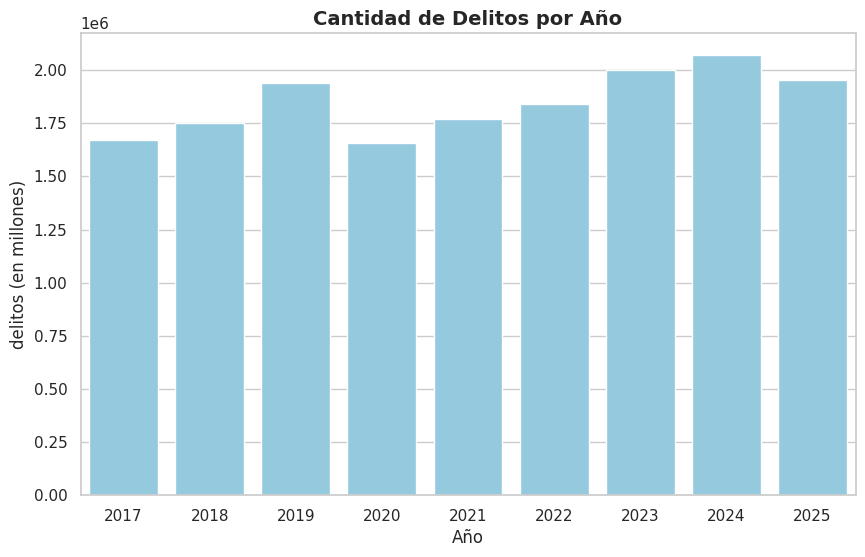

In [107]:
# Graficamos

# Configurar el estilo del gráfico
sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Crear el gráfico de barras verticales
ax = sb.barplot(
    data=df_delito_por_anio,
    x='anio',
    y='cantidad_hechos',
    color='skyblue'
)

# Configurar títulos y etiquetas de los ejes
plt.title('Cantidad de Delitos por Año', fontsize=14, fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('delitos (en millones)', fontsize=12)  # Eje Y nombrado como "delitos"

# Mostrar el gráfico
plt.show()

Para analizar el Área Metropolitana de Buenos Aires (AMBA) (15 comunas de CABA y 24 partidos del Conurbano), se aplicaron dos criterios clave en el código:

Filtro Geográfico Anti-Homonimia: Para evitar confundir municipios de Buenos Aires con departamentos de otras provincias que se llaman igual (ej. San Martín o San Isidro), se aplicó un filtro estricto por provincia_nombre y Departamentos antes de unir los datos.

Proyección y estimación de variables socioeconómicas intercensales (2017–2025)

Dado que las encuestas periódicas (como la EPH) no ofrecen representatividad estadística individual a nivel de comuna o partido del Conurbano, los valores anuales de Población, NBI, Secundario Completo e Índice de Calidad de Vida (ICV) se estimaron mediante una interpolación lineal basada en los datos observados de los Censos Nacionales de Población, Hogares y Viviendas de 2010 y 2022.

Limitaciones de las estimaciones socioeconómicas:

Extrapolación (2023–2025): Para los años posteriores al último censo disponible (2023, 2024 y 2025), se aplicó una extrapolación lineal, asumiendo de manera teórica que la tendencia intercensal observada entre 2010 y 2022 se mantuvo sin variaciones.

Efecto de la suavización interanual: La interpolación lineal asume un comportamiento inercial y constante año tras año. Por lo tanto, no refleja posibles fluctuaciones breves o shocks macroeconómicos y sociales ocurridos en años intermedios.

In [108]:
# 1. Matriz de Datos Censales 2010 y 2022 para el Conurbano Bonaerense (24 Partidos)
# Variables: Poblacion, % NBI, % Secundario Completo, Indice Calidad de Vida (0 a 10)
datos_conurbano = {
    'Departamentos': [
        'Avellaneda', 'Almirante Brown', 'Berazategui', 'Esteban Echeverría',
        'Ezeiza', 'Florencio Varela', 'General San Martín', 'Hurlingham',
        'Ituzaingó', 'José C. Paz', 'La Matanza', 'Lanús', 'Lomas de Zamora',
        'Malvinas Argentinas', 'Merlo', 'Moreno', 'Morón', 'Quilmes',
        'San Fernando', 'San Isidro', 'San Miguel', 'Tigre',
        'Tres de Febrero', 'Vicente López'
    ],
    'Pob 2010': [342677, 552102, 324244, 300959, 163722, 426005, 414196, 181241, 167824, 265981, 1775816, 459263, 616279, 322375, 528494, 452505, 321109, 582943, 163207, 292878, 276190, 376381, 340071, 269420],
    'Pob 2022': [370939, 585852, 360582, 339070, 203283, 497818, 450335, 187122, 179237, 323908, 1837774, 462020, 694330, 351588, 585686, 574374, 334178, 633391, 172524, 298777, 326215, 447307, 366370, 283510],
    'NBI 2010': [5.8, 12.1, 8.4, 12.8, 12.2, 16.4, 8.2, 8.1, 7.2, 16.1, 11.8, 6.7, 10.9, 13.5, 12.9, 14.8, 5.1, 10.1, 9.3, 4.8, 11.2, 10.5, 5.9, 3.2],
    'NBI 2022': [4.2, 9.1, 6.3, 9.7, 9.1, 12.5, 6.1, 6.0, 5.3, 12.2, 8.9, 5.0, 8.2, 10.1, 9.6, 11.1, 3.8, 7.5, 7.0, 3.6, 8.4, 7.8, 4.4, 2.4],
    'Educ 2010': [52.1, 41.5, 43.8, 38.9, 39.2, 32.8, 48.3, 47.9, 49.1, 31.5, 39.7, 50.2, 45.3, 35.8, 36.1, 34.2, 58.4, 46.5, 47.2, 65.8, 42.1, 46.8, 53.1, 71.4],
    'Educ 2022': [61.4, 50.8, 52.9, 48.1, 48.5, 41.9, 57.6, 56.8, 58.2, 40.8, 48.9, 59.5, 54.6, 46.9, 45.2, 43.1, 67.2, 55.8, 56.1, 73.9, 51.3, 55.9, 62.3, 79.1],
    'ICV 2010': [7.2, 5.8, 6.4, 5.6, 5.7, 4.9, 6.9, 6.8, 7.0, 4.8, 5.8, 7.0, 6.2, 5.4, 5.3, 5.1, 7.6, 6.3, 6.5, 8.2, 5.9, 6.3, 7.1, 8.7],
    'ICV 2022': [7.6, 6.3, 6.9, 6.1, 6.2, 5.4, 7.3, 7.2, 7.4, 5.3, 6.3, 7.4, 6.7, 5.9, 5.8, 5.6, 8.0, 6.8, 7.0, 8.5, 6.4, 6.8, 7.5, 9.0]
}

# 2. Matriz de Datos Censales 2010 y 2022 para CABA (15 Comunas)
datos_caba = {
    'Departamentos': [f'Comuna {i}' for i in range(1, 16)],
    'Pob 2010': [205886, 157932, 187537, 218245, 179005, 176076, 220591, 187227, 161707, 166022, 189832, 200116, 235966, 225970, 182574],
    'Pob 2022': [223282, 158316, 192847, 230508, 193276, 184138, 240868, 204641, 169508, 171797, 203484, 213914, 265190, 249016, 197240],
    'NBI 2010': [8.9, 2.1, 4.3, 15.2, 3.8, 2.2, 3.1, 19.8, 11.2, 4.1, 2.9, 1.8, 2.0, 1.5, 2.4],
    'NBI 2022': [6.8, 1.4, 3.1, 11.5, 2.7, 1.5, 2.2, 14.9, 8.1, 2.9, 2.1, 1.2, 1.4, 1.0, 1.7],
    'Educ 2010': [68.5, 88.2, 81.4, 49.8, 71.2, 82.5, 75.1, 43.2, 58.9, 70.4, 76.8, 83.1, 85.4, 89.1, 82.0],
    'Educ 2022': [75.2, 92.8, 87.1, 58.4, 78.5, 88.1, 82.0, 52.1, 67.2, 77.9, 83.5, 89.0, 90.8, 93.5, 88.2],
    'ICV 2010': [6.8, 9.2, 8.4, 5.2, 7.5, 8.6, 7.8, 4.5, 6.1, 7.4, 8.1, 8.7, 8.0, 9.3, 8.5],
    'ICV 2022': [7.2, 9.5, 8.8, 5.8, 7.9, 8.9, 8.2, 5.1, 6.6, 7.8, 8.5, 9.0, 8.5, 9.6, 8.9]
}

# Unimos ambas estructuras de origen
df_base_censal = pd.concat([pd.DataFrame(datos_conurbano), pd.DataFrame(datos_caba)], ignore_index=True)

# 3. Interpolación y Proyección Lineal para el período 2017-2025
registros_amba = []
anios_tp = range(2017, 2026)

for idx, row in df_base_censal.iterrows():
    depto = row['Departamentos']

    m_pob = (row['Pob 2022'] - row['Pob 2010']) / 12
    m_nbi = (row['NBI 2022'] - row['NBI 2010']) / 12
    m_educ = (row['Educ 2022'] - row['Educ 2010']) / 12
    m_icv = (row['ICV 2022'] - row['ICV 2010']) / 12

    for anio in anios_tp:
        registros_amba.append({
            'Año': anio,
            'Departamentos': depto,
            'Poblacion_Proyectada': int(round(row['Pob 2010'] + m_pob * (anio - 2010))),
            'Pct_NBI_Estimado': round(row['NBI 2010'] + m_nbi * (anio - 2010), 2),
            'Pct_Secundario_Completo': round(row['Educ 2010'] + m_educ * (anio - 2010), 2),
            'Indice_Calidad_Vida': round(row['ICV 2010'] + m_icv * (anio - 2010), 2)
        })

df_proyecciones_amba = pd.DataFrame(registros_amba)

# 4. Guardar archivo CSV local
df_proyecciones_amba.to_csv("proyecciones_socioeconomicas_amba_2017_2025.csv", index=False)

# 5. Estandarización de nombres de columnas en df_delito
renombres_delito = {}
for col in df_delito.columns:
    col_clean = col.strip().lower()
    if 'anio' in col_clean or 'año' in col_clean:
        renombres_delito[col] = 'Año'
    elif 'depa' in col_clean:
        renombres_delito[col] = 'Departamentos'

df_delito = df_delito.rename(columns=renombres_delito)

# Convertir la columna 'Año' a tipo entero
df_delito['Año'] = df_delito['Año'].astype(int)
df_proyecciones_amba['Año'] = df_proyecciones_amba['Año'].astype(int)

# -------------------------------------------------------------------
# NUEVO: Filtrado preventivo de df_delito para AMBA (CABA + 24 Partidos)
# Evita traer filas de Córdoba, Santiago del Estero, etc., en el merge
# -------------------------------------------------------------------
condicion_caba = (df_delito['provincia_nombre'] == 'Ciudad Autónoma de Buenos Aires')
condicion_pba = (df_delito['provincia_nombre'] == 'Buenos Aires') & (df_delito['Departamentos'].isin(datos_conurbano['Departamentos']))

df_delito_amba = df_delito[condicion_caba | condicion_pba].copy()

# 6. Merge final usando el dataset de delito ya filtrado
df_amba = pd.merge(
    df_delito_amba,
    df_proyecciones_amba,
    on=['Año', 'Departamentos'],
    how='inner'
)

# 7. Detección automática de la columna de hechos y cálculo de la tasa corregida
col_hechos = [c for c in df_amba.columns if 'hecho' in c.lower() or 'cantidad' in c.lower()][0]
df_amba['Tasa_Delito_Calculada'] = (df_amba[col_hechos] / df_amba['Poblacion_Proyectada']) * 100000

# Verificamos la forma, provincias presentes y primeras filas del dataset consolidado
print(f"Dataset df_amba generado con {df_amba.shape[0]} filas y {df_amba.shape[1]} columnas.")
print("Provincias incluidas en df_amba:", df_amba['provincia_nombre'].unique())
df_amba.head()

Dataset df_amba generado con 20811 filas y 14 columnas.
Provincias incluidas en df_amba: ['Ciudad Autónoma de Buenos Aires' 'Buenos Aires']


,Año,provincia_nombre,Departamentos,codigo_delito_snic_nombre,cantidad_hechos,cantidad_victimas_masc,cantidad_victimas_fem,cantidad_victimas_sd,tasa_hechos,Poblacion_Proyectada,Pct_NBI_Estimado,Pct_Secundario_Completo,Indice_Calidad_Vida,Tasa_Delito_Calculada
0,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Homicidios dolosos,25,21.0,4.0,0.0,9.870850,216034,7.67,72.41,7.03,11.572253
1,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Abusos sexuales con acceso carnal (violaciones),14,0.0,14.0,2.0,5.527676,216034,7.67,72.41,7.03,6.480461
2,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Otros delitos contra la integridad sexual,190,22.0,171.0,16.0,75.018458,216034,7.67,72.41,7.03,87.949119
3,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Delitos contra el estado civil,0,NaN,NaN,NaN,0.000000,216034,7.67,72.41,7.03,0.000000
4,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Amenazas,1074,NaN,NaN,NaN,424.051707,216034,7.67,72.41,7.03,497.143968


Asociación y correlación espacial: El presente análisis evalúa la asociación estadística entre las condiciones socioeconómicas agregadas y la frecuencia de hechos delictivos a nivel territorial (Comunas de CABA y Partidos del Conurbano). Los resultados permiten afirmar si las zonas con mayor NBI o menor calidad de vida registran una mayor tasa de delitos denunciados.

Ausencia de causalidad e inferencia individual: Los hallazgos no implican una relación de causalidad directos (las condiciones socioeconómicas no "causan" el delito de forma directa), ya que existen factores omitidos relevantes como la densidad poblacional flotante, la presencia policial o la tasa de denuncia. Asimismo, los datos representan agregados geográficos y no deben extrapolarse al comportamiento individual de las personas.

### Gráfico de variación de la tasa de delitos, 2017-2025

Para comparar cómo cambió la tasa de delitos en cada partido del Conurbano y en cada comuna de CABA,
se calcula la variación porcentual entre 2017 y 2025 y se representa con un gráfico de barras ordenado
de menor a mayor.

**Uso del color.** Las barras se colorean en rojo si la tasa aumentó y en verde si disminuyó, de modo que
el sentido del cambio se lea de un vistazo. Además, el tono se hace más oscuro cuanto mayor es la
variación dentro de cada grupo. Para lograrlo se utiliza el módulo `colorsys` de la biblioteca estándar
de Python, que permite definir un color por su tono, su claridad y su saturación (HLS) y convertirlo a
RGB, el formato que usa matplotlib. De este modo se mantiene fija la saturación y el tono (rojo o verde) y
solo se varía la claridad, lo que produce un degradado uniforme sin que el color se vuelva grisáceo.
Esta opción no requiere instalar ninguna librería adicional.

**Cómo leer el gráfico.** La intensidad del color refleja la posición de cada barra dentro de su grupo
(rojo o verde), no su magnitud, que se lee en las etiquetas con el porcentaje.

**Aclaraciones sobre la tasa de delitos**

- Los datos corresponden a delitos denunciados y registrados (SNIC), no a la totalidad de los delitos
  ocurridos. Los hechos que no se denuncian no están incluidos y la proporción puede variar según la zona.
- La tasa se calcula cada 100.000 habitantes residentes. No considera a las personas que trabajan, estudian
  o circulan en cada lugar sin vivir en él (población flotante), por lo que en zonas de mucho tránsito
  comercial o laboral, como la Comuna 1 o Morón, la tasa puede resultar más alta de lo que sugiere el
  riesgo para los residentes.

Comunas incluidas: 15


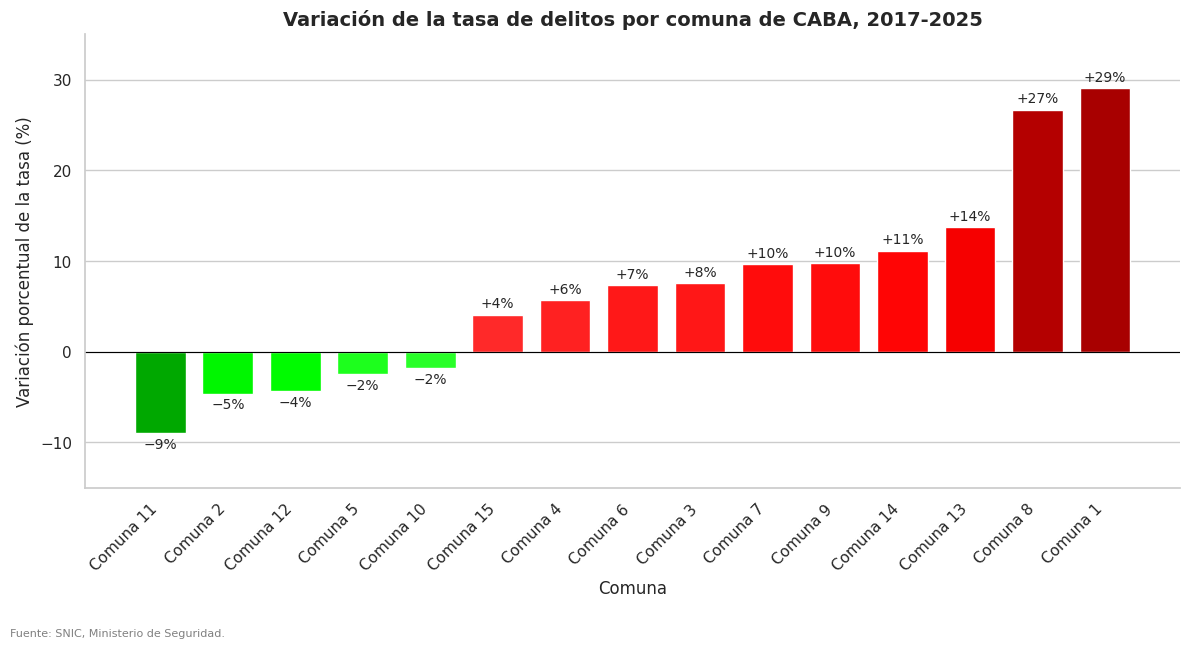

In [109]:
# 1) Filtrar CABA y excluir los hechos sin comuna determinada
base_caba = df_delito[
    (df_delito["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires") &
    (df_delito["Departamentos"] != "Departamento sin determinar")
]
print("Comunas incluidas:", base_caba["Departamentos"].nunique())   # control: tienen que ser 15

# 2) Tasa total por comuna y año: se suman las tasas de todos los tipos de delito,
#    porque dentro de una misma comuna todas comparten la misma población
tasa_comuna_anio = (
    base_caba
    .groupby(["Año", "Departamentos"], as_index=False)["tasa_hechos"]
    .sum()
)

# 3) Tabla con una fila por comuna y una columna por año
tabla_caba = tasa_comuna_anio.pivot(index="Departamentos", columns="Año", values="tasa_hechos")

# 4) Variación porcentual entre 2017 y 2025, ordenada de menor a mayor (forma de escalera)
variacion_caba = ((tabla_caba[2025] / tabla_caba[2017]) - 1) * 100
variacion_caba = variacion_caba.sort_values()

# 5) Colores: rojo si la tasa subió, verde si bajó (cuanto mayor la variación, más oscuro el tono)
def color(v, tono, v_min, v_max, l_claro=0.58, l_oscuro=0.33):
    t = 0 if v_max == v_min else (abs(v) - v_min) / (v_max - v_min)
    return colorsys.hls_to_rgb(tono, l_claro - t * (l_claro - l_oscuro), 1.0)

pos = variacion_caba[variacion_caba > 0].abs()    # comunas donde la tasa subió
neg = variacion_caba[variacion_caba < 0].abs()    # comunas donde la tasa bajó

colores = [
    color(v, 0.0, pos.min(), pos.max()) if v > 0
    else color(v, 1/3, neg.min(), neg.max())
    for v in variacion_caba
]

# 6) Gráfico de barras
fig, ax = plt.subplots(figsize=(12, 6.5))
barras = ax.bar(variacion_caba.index, variacion_caba.values, color=colores, width=0.75)
ax.bar_label(barras, labels=[f"{v:+.0f}%".replace("-", "−") for v in variacion_caba], padding=3, fontsize=10)

ax.axhline(0, color="black", linewidth=0.8)                                   # línea del cero
ax.set_title("Variación de la tasa de delitos por comuna de CABA, 2017-2025", fontsize=14, fontweight="bold")
ax.set_xlabel("Comuna")
ax.set_ylabel("Variación porcentual de la tasa (%)")
ax.set_xticks(range(len(variacion_caba)))
ax.set_xticklabels(variacion_caba.index, rotation=45, ha="right")
ax.grid(axis="x", visible=False)                                              # grilla solo horizontal
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(variacion_caba.min() - 6, variacion_caba.max() + 6)               # margen para las etiquetas
fig.text(0.01, 0.008, "Fuente: SNIC, Ministerio de Seguridad.", fontsize=8, color="gray")
fig.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("variacion_caba_escalera.png", dpi=110)
plt.show()

**Interpretación.** Entre 2017 y 2025 la tasa de delitos denunciados subió en 10 de las 15 comunas y bajó en
5. Los cambios son moderados: van desde -9% (Comuna 11) hasta +29% (Comuna 1). Las que más crecieron son la
Comuna 1 (+29%) y la Comuna 8 (+27%), seguidas por la 13 (+14%); las que más bajaron son la 11 (-9%), la 2
(-5%) y la 12 (-4%).

Esto muestra que el cambio no fue parejo dentro de CABA: hay comunas donde la tasa aumentó bastante y otras
donde bajó un poco. Estas variaciones comparan solo dos años (2017 y 2025), así que no muestran qué pasó en el
medio.

Hay que tener en cuenta lo que aclaramos arriba sobre la población flotante, que puede afectar a la Comuna 1,
y que algunas categorías de delito figuran con valor 0 en 2017, por lo que parte de la suba puede deberse a
hechos que no estaban contabilizados al inicio.

### Distribución de los barrios por comuna de CABA

La Ciudad Autónoma de Buenos Aires está dividida en 15 comunas que agrupan sus 48 barrios. Para facilitar la interpretación del gráfico, se detalla qué barrios corresponden a cada comuna.

- **Comuna 1:** Retiro, San Nicolás, Puerto Madero, San Telmo, Montserrat y Constitución.
- **Comuna 2:** Recoleta.
- **Comuna 3:** Balvanera y San Cristóbal.
- **Comuna 4:** La Boca, Barracas, Parque Patricios y Nueva Pompeya.
- **Comuna 5:** Almagro y Boedo.
- **Comuna 6:** Caballito.
- **Comuna 7:** Flores y Parque Chacabuco.
- **Comuna 8:** Villa Soldati, Villa Riachuelo y Villa Lugano.
- **Comuna 9:** Liniers, Mataderos y Parque Avellaneda.
- **Comuna 10:** Villa Real, Monte Castro, Versalles, Floresta, Vélez Sarsfield y Villa Luro.
- **Comuna 11:** Villa General Mitre, Villa Devoto, Villa del Parque y Villa Santa Rita.
- **Comuna 12:** Coghlan, Saavedra, Villa Urquiza y Villa Pueyrredón.
- **Comuna 13:** Núñez, Belgrano y Colegiales.
- **Comuna 14:** Palermo.
- **Comuna 15:** Chacarita, Villa Crespo, La Paternal, Villa Ortúzar, Agronomía y Parque Chas.

Esta distribución permite identificar las zonas representadas en el gráfico y comparar la evolución de los hechos delictivos entre las distintas comunas durante el período 2017-2025.

Para analizar el Conurbano bonaerense se utiliza el listado de los 24 partidos de la provincia de
Buenos Aires que rodean a la Ciudad Autónoma de Buenos Aires. El dataset del SNIC no incluye esta
clasificación, por lo que se filtra por nombre de departamento.

Partidos incluidos: 24


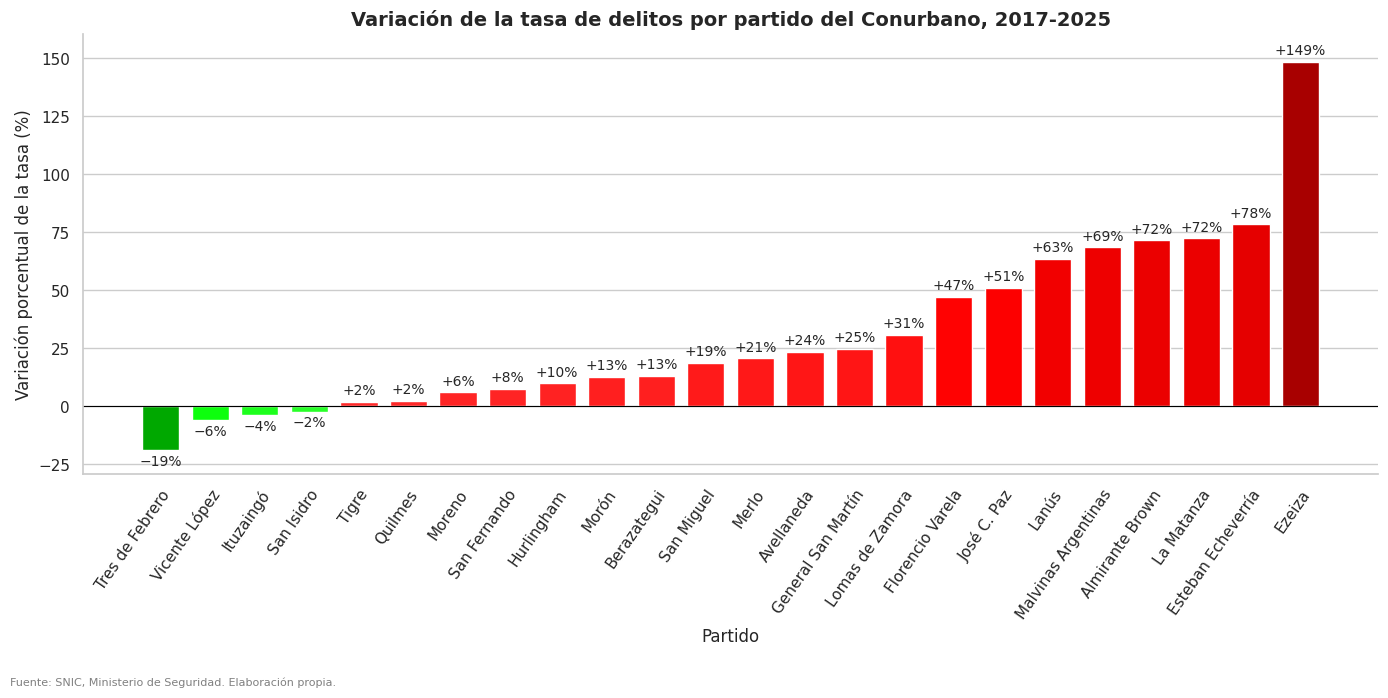

In [110]:
# 0) Definir la lista de los 24 partidos del Conurbano bonaerense
partidos_conurbano = [
    "Almirante Brown", "Avellaneda", "Berazategui", "Esteban Echeverría",
    "Ezeiza", "Florencio Varela", "General San Martín", "Hurlingham",
    "Ituzaingó", "José C. Paz", "La Matanza", "Lanús", "Lomas de Zamora",
    "Malvinas Argentinas", "Merlo", "Moreno", "Morón", "Quilmes",
    "San Fernando", "San Isidro", "San Miguel", "Tigre",
    "Tres de Febrero", "Vicente López"
]

# 1) Filtrar provincia de Buenos Aires y los 24 partidos de la lista
#    (se filtra por provincia Y por nombre, porque hay partidos con el mismo nombre en otras provincias)
base = df_delito[
    (df_delito["provincia_nombre"] == "Buenos Aires") &
    (df_delito["Departamentos"].isin(partidos_conurbano))
]
print("Partidos incluidos:", base["Departamentos"].nunique())   # control: tienen que ser 24

# 2) Tasa total por partido y año: se suman las tasas de todos los tipos de delito,
#    porque dentro de un mismo partido todas comparten la misma población
tasa_partido_anio = (
    base
    .groupby(["Año", "Departamentos"], as_index=False)["tasa_hechos"]
    .sum()
)

# 3) Tabla con una fila por partido y una columna por año
tabla = tasa_partido_anio.pivot(index="Departamentos", columns="Año", values="tasa_hechos")

# 4) Variación porcentual entre 2017 y 2025, ordenada de menor a mayor (forma de escalera)
variacion = ((tabla[2025] / tabla[2017]) - 1) * 100
variacion = variacion.sort_values()

# 5) Colores: rojo si la tasa subió, verde si bajó (cuanto mayor la variación, más oscuro el tono)
def color(v, tono, v_min, v_max, l_claro=0.58, l_oscuro=0.33):
    t = 0 if v_max == v_min else (abs(v) - v_min) / (v_max - v_min)
    return colorsys.hls_to_rgb(tono, l_claro - t * (l_claro - l_oscuro), 1.0)

pos = variacion[variacion > 0].abs()    # partidos donde la tasa subió
neg = variacion[variacion < 0].abs()    # partidos donde la tasa bajó

colores = [
    color(v, 0.0, pos.min(), pos.max()) if v > 0
    else color(v, 1/3, neg.min(), neg.max())
    for v in variacion
]

# 6) Gráfico de barras
fig, ax = plt.subplots(figsize=(14, 7))
barras = ax.bar(variacion.index, variacion.values, color=colores, width=0.75)
ax.bar_label(barras, labels=[f"{v:+.0f}%".replace("-", "−") for v in variacion], padding=3, fontsize=10)

ax.axhline(0, color="black", linewidth=0.8)                                   # línea del cero
ax.set_title("Variación de la tasa de delitos por partido del Conurbano, 2017-2025", fontsize=14, fontweight="bold")
ax.set_xlabel("Partido")
ax.set_ylabel("Variación porcentual de la tasa (%)")
ax.set_xticks(range(len(variacion)))
ax.set_xticklabels(variacion.index, rotation=55, ha="right", rotation_mode="anchor")
ax.grid(axis="x", visible=False)                                              # grilla solo horizontal
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(variacion.min() - 10, variacion.max() + 12)                       # margen para las etiquetas
fig.text(0.01, 0.008, "Fuente: SNIC, Ministerio de Seguridad. Elaboración propia.", fontsize=8, color="gray")
fig.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("variacion_conurbano_escalera.png", dpi=110)
plt.show()

**Interpretación.** En el Conurbano la tasa aumentó en 20 de los 24 partidos y bajó en 4 (Tres de Febrero,
-19%; Vicente López, -6%; Ituzaingó, -4%; y San Isidro, -2%). Las diferencias entre partidos son mucho
mayores que en CABA: van desde -19% hasta +149% en Ezeiza. Después de Ezeiza, los que más crecieron son
Esteban Echeverría (+78%), La Matanza (+72%) y Almirante Brown (+72%).

Esto quiere decir que el aumento del Conurbano no es homogéneo: se concentra en unos pocos partidos, y hay
otros donde la tasa casi no cambió o bajó.

Una advertencia importante: el SNIC cambia la población que usa para calcular la tasa en 2022 (por ejemplo,
en La Matanza baja de unos 2,1 millones en 2017 a unos 1,8 millones en 2025). Como la población es el
denominador, parte del aumento de la tasa en algunos partidos puede deberse a ese cambio y no a más delitos.
También valen las aclaraciones de arriba sobre las categorías con valor 0 en 2017.

### Tipos de delito denunciados, 2017-2025

El gráfico muestra qué porcentaje del total de hechos de cada zona corresponde a cada tipo de delito. Se
muestran los 12 más frecuentes y el resto se agrupa en "Otros". Los porcentajes son dentro de cada zona, por
lo que no indican en cuál hay más delitos.

"Otros" agrupa las 54 categorías restantes del SNIC (por ejemplo daños, tentativas de hurto, estafas
virtuales y delitos de drogas). Ninguna supera el 1,4% de los hechos por sí sola, y juntas suman 10,2% en
cada zona. No hay que confundirlo con "Otros delitos contra la propiedad", "Otros delitos contra la
seguridad pública" y "Otros previstos en leyes especiales", que son categorías del propio SNIC con ese nombre.

“Robos” y “Tentativas de robo” no incluyen los casos agravados por lesiones o muertes, que el SNIC cuenta en categorías aparte (y que acá quedan dentro de “Otros”).

In [111]:
# Base de las dos zonas, a partir de df_delito_amba (ya filtrada en la celda del merge)
base_zonas = df_delito_amba[df_delito_amba["Departamentos"] != "Departamento sin determinar"].copy()
base_zonas["zona"] = np.where(
    base_zonas["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires", "CABA", "Conurbano"
)

Suma de porcentajes por zona:
zona
CABA         100.0
Conurbano    100.0
dtype: float64


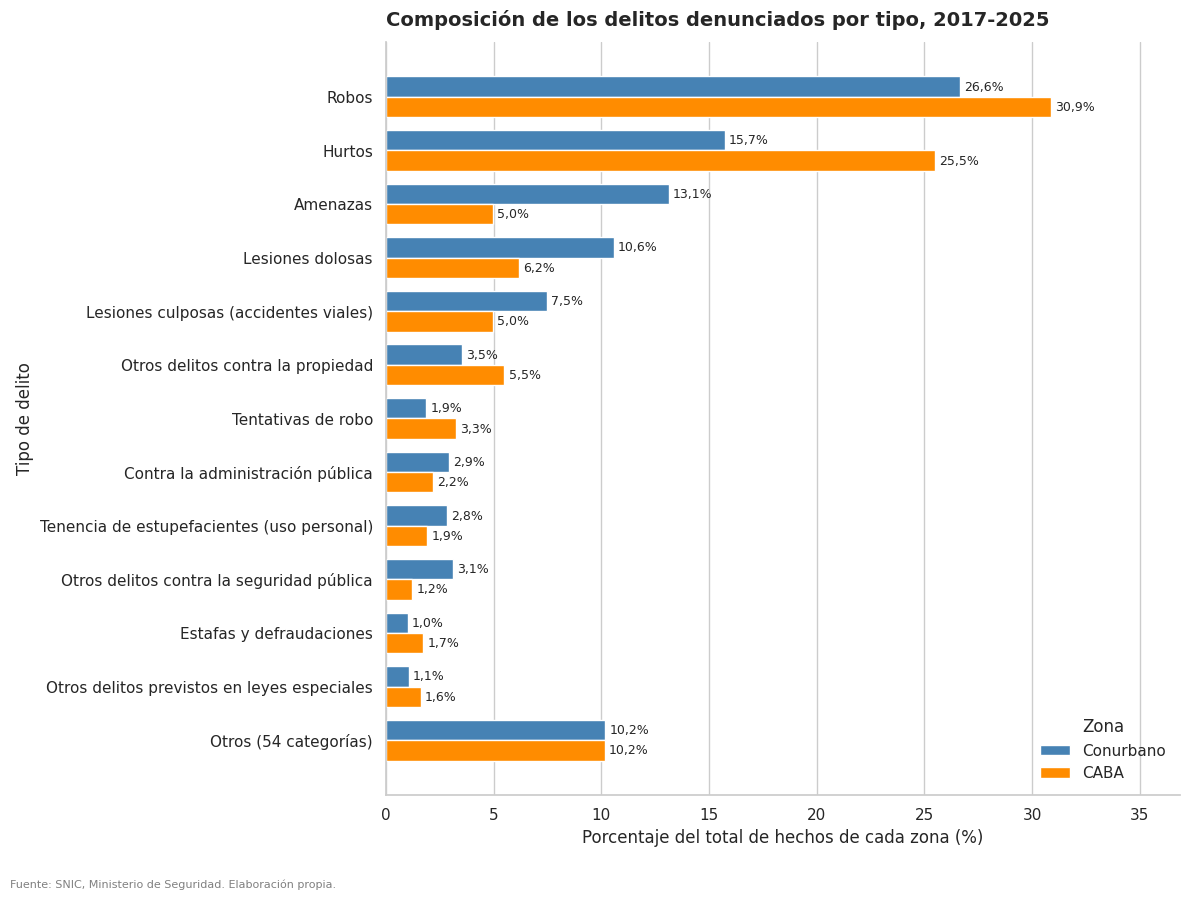

In [112]:
# 1) Nombres cortos para los tipos de delito más largos (así entran en el gráfico)
nombres_cortos = {
    "Robos (excluye los agravados por el resultado de lesiones y/o muertes)": "Robos",
    "Lesiones culposas en Accidentes Viales": "Lesiones culposas (accidentes viales)",
    "Tentativas de robo (excluye las agravadas por el res. de lesiones y/o muerte)": "Tentativas de robo",
    "Delitos contra la administración pública": "Contra la administración pública",
    "Estafas y defraudaciones (no incluye virtuales) y usura": "Estafas y defraudaciones",
    "Tenencia simple atenuada para uso personal de estupefacientes": "Tenencia de estupefacientes (uso personal)",
}
# Si el tipo está en el diccionario se usa el nombre corto; si no, se deja el nombre original
base_zonas["tipo"] = base_zonas["codigo_delito_snic_nombre"].map(nombres_cortos).fillna(base_zonas["codigo_delito_snic_nombre"])

# 2) Hechos por tipo de delito y zona (una fila por tipo, una columna por zona)
hechos = base_zonas.groupby(["zona", "tipo"])["cantidad_hechos"].sum().unstack(0).fillna(0)

# 3) Porcentaje de cada tipo sobre el total de hechos de su zona
pct = hechos / hechos.sum() * 100

# 4) Nos quedamos con los 12 tipos más frecuentes y juntamos el resto en una sola fila
top = pct.sum(axis=1).sort_values(ascending=False).head(12).index
tabla_tipos = pct.loc[top]
nombre_otros = f"Otros ({len(pct) - 12} categorías)"          # cuántas categorías se agrupan
tabla_tipos.loc[nombre_otros] = 100 - tabla_tipos.sum()
tabla_tipos = tabla_tipos.iloc[::-1]          # se invierte el orden para que el más frecuente quede arriba
# Control: los porcentajes de cada zona tienen que sumar 100
print("Suma de porcentajes por zona:")
print(tabla_tipos.sum().round(1))

# 5) Gráfico de barras agrupadas: una barra por zona para cada tipo de delito
y = np.arange(len(tabla_tipos))               # posición de cada tipo en el eje vertical
alto = 0.38                                   # alto de cada barra
fig, ax = plt.subplots(figsize=(12, 9))
b1 = ax.barh(y + alto/2, tabla_tipos["Conurbano"], alto, label="Conurbano", color="steelblue")
b2 = ax.barh(y - alto/2, tabla_tipos["CABA"], alto, label="CABA", color="darkorange")
for barras, zona in [(b1, "Conurbano"), (b2, "CABA")]:
    ax.bar_label(barras, labels=[f"{v:.1f}%".replace(".", ",") for v in tabla_tipos[zona]], padding=3, fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(tabla_tipos.index)
ax.set_title("Composición de los delitos denunciados por tipo, 2017-2025", fontsize=14, fontweight="bold", loc="left", pad=12)
ax.set_xlabel("Porcentaje del total de hechos de cada zona (%)")
ax.set_ylabel("Tipo de delito")
ax.set_xlim(0, tabla_tipos.max().max() + 6)  # deja lugar a la derecha para las etiquetas
ax.grid(axis="y", visible=False)             # grilla solo vertical (sobre los valores)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Zona", frameon=False, loc="lower right")
fig.text(0.01, 0.005, "Fuente: SNIC, Ministerio de Seguridad. Elaboración propia.", fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("tipos_delito.png", dpi=110)
plt.show()

Los robos y los hurtos son los delitos más denunciados en las dos zonas, pero pesan
distinto: en CABA suman un 56% de los hechos (30,9% robos y 25,5% hurtos) y en el Conurbano un 42%
(26,6% y 15,7%). Del lado del Conurbano pesan más las amenazas (13,1% contra 5,0% en CABA) y las lesiones
dolosas (10,6% contra 6,2%), es decir, delitos contra las personas.

Esto quiere decir que el perfil de lo que se denuncia en CABA está más concentrado en delitos contra la
propiedad, mientras que en el Conurbano tiene más peso lo que ocurre entre personas. Como los porcentajes
son dentro de cada zona, no dicen en cuál hay más delitos (eso se ve en el gráfico de la tasa).

Hay que tener en cuenta que son delitos denunciados: no todos los tipos se denuncian por igual, y puede
haber diferencias entre zonas en cuánto se denuncia.

### Víctimas por sexo según tipo de hecho, 2017-2025

El gráfico muestra el porcentaje de víctimas mujeres, varones y "sin dato" en cada tipo de delito. El SNIC
solo registra el sexo en algunos delitos contra las personas, por lo que no se incluyen robos ni hurtos.
La categoría "sin dato" es mucho más grande en CABA, lo que hay que tener en cuenta al comparar.

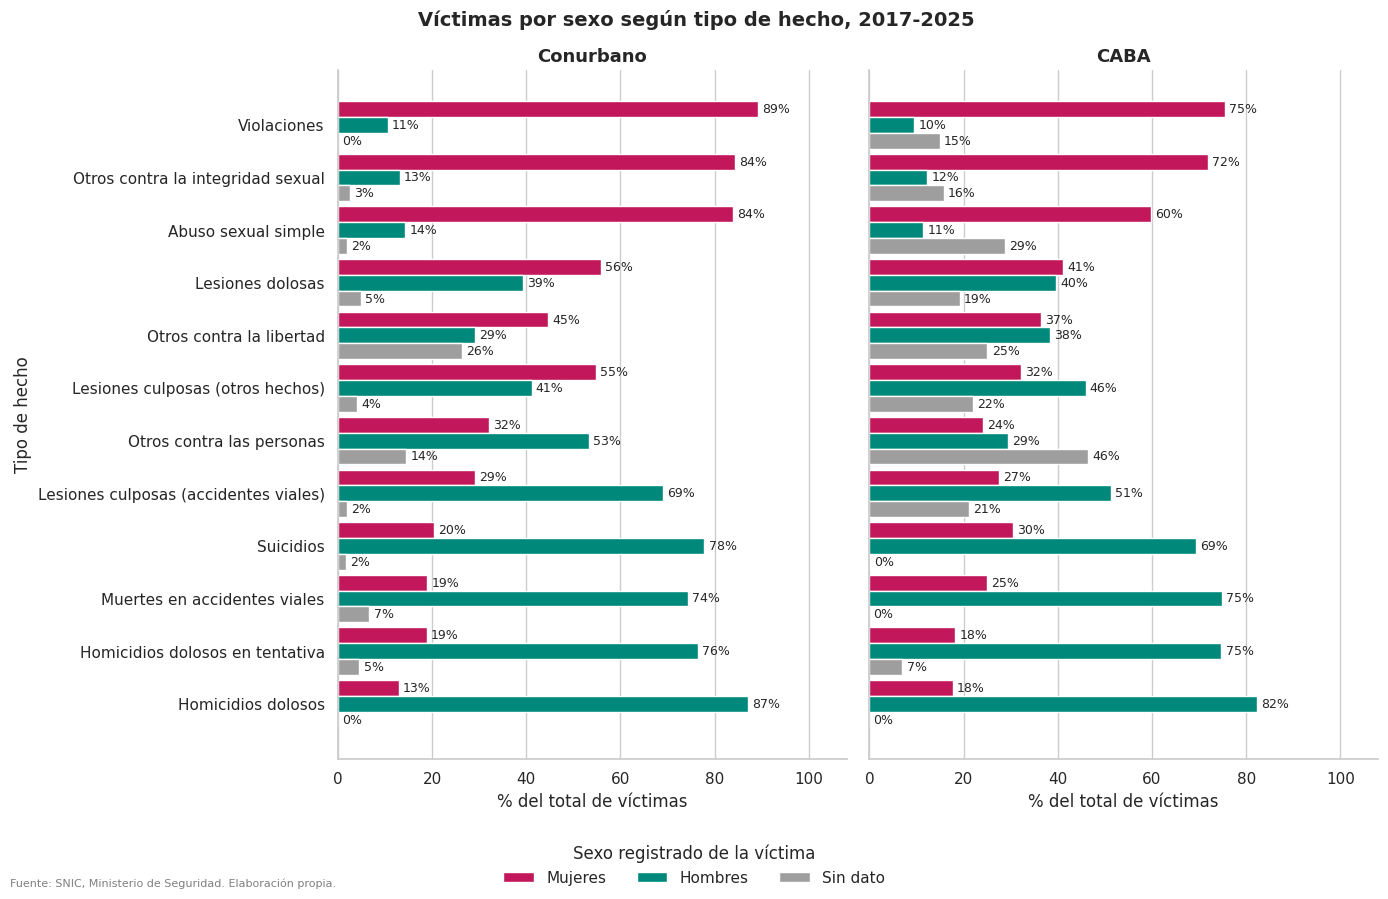

In [113]:
# 1) Las columnas de víctimas por sexo no se cargaron al inicio: se leen acá, en una tabla aparte
df_vict = pd.read_csv(url, usecols=[0, 2, 4, 6, 9, 10, 11], low_memory=False)   # año, provincia, departamento, delito, víctimas masc / fem / sin dato
df_vict = df_vict[(df_vict["anio"] >= 2017) & (df_vict["anio"] <= 2025)]

# 2) Mismas dos zonas que en el resto del notebook (se filtra por provincia y departamento)
es_conurbano = (df_vict["provincia_nombre"] == "Buenos Aires") & (df_vict["departamento_nombre"].isin(partidos_conurbano))
es_caba = (df_vict["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires") & (df_vict["departamento_nombre"] != "Departamento sin determinar")
df_vict = df_vict[es_conurbano | es_caba].copy()
df_vict["zona"] = np.where(es_caba[df_vict.index], "CABA", "Conurbano")

# 3) Solo los tipos de hecho con víctimas por sexo que se van a mostrar (con nombres cortos)
tipos_sexo = {
    "Abusos sexuales con acceso carnal (violaciones)": "Violaciones",
    "Abuso sexual simple": "Abuso sexual simple",
    "Otros delitos contra la integridad sexual": "Otros contra la integridad sexual",
    "Lesiones dolosas": "Lesiones dolosas",
    "Otros delitos contra la libertad": "Otros contra la libertad",
    "Lesiones culposas por otros hechos": "Lesiones culposas (otros hechos)",
    "Otros delitos contra las personas": "Otros contra las personas",
    "Lesiones culposas en Accidentes Viales": "Lesiones culposas (accidentes viales)",
    "Muertes en accidentes viales": "Muertes en accidentes viales",
    "Homicidios dolosos en grado de tentativa": "Homicidios dolosos en tentativa",
    "Suicidios (consumados)": "Suicidios",
    "Homicidios dolosos": "Homicidios dolosos",
}
v = df_vict[df_vict["codigo_delito_snic_nombre"].isin(tipos_sexo)].copy()
v["tipo"] = v["codigo_delito_snic_nombre"].map(tipos_sexo)

# 4) Víctimas por zona y tipo, y porcentaje de cada sexo sobre TODAS las víctimas (incluye "sin dato")
g = v.groupby(["zona", "tipo"])[["cantidad_victimas_fem", "cantidad_victimas_masc", "cantidad_victimas_sd"]].sum()
total = g.sum(axis=1)                                            # total de víctimas de cada zona y tipo
g["Mujeres"] = g["cantidad_victimas_fem"] / total * 100
g["Hombres"] = g["cantidad_victimas_masc"] / total * 100
g["Sin dato"] = g["cantidad_victimas_sd"] / total * 100

# 5) Orden de los tipos: de menos a más proporción de mujeres (entre las víctimas con sexo conocido)
orden = (g["Mujeres"] / (g["Mujeres"] + g["Hombres"])).groupby("tipo").mean().sort_values().index

# 6) Gráfico: un panel por zona, con tres barras (mujeres, hombres, sin dato) por tipo de hecho
fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharey=True)
y = np.arange(len(orden)); alto = 0.3
for ax, zona in zip(axes, ["Conurbano", "CABA"]):
    t = g.loc[zona].loc[orden]
    for desp, col, color in [(alto, "Mujeres", "#c2185b"), (0, "Hombres", "#00897b"), (-alto, "Sin dato", "#9e9e9e")]:
        b = ax.barh(y + desp, t[col], alto, label=col, color=color)
        ax.bar_label(b, fmt="%.0f%%", padding=3, fontsize=9)
    ax.set_title(zona, fontsize=13, fontweight="bold")
    ax.set_xlabel("% del total de víctimas")
    ax.set_xlim(0, 108)
    ax.grid(axis="y", visible=False)                              # grilla solo vertical (sobre los valores)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(y); axes[0].set_yticklabels(orden); axes[0].set_ylabel("Tipo de hecho")

# Leyenda debajo del gráfico, para que no tape las barras
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Sexo registrado de la víctima", loc="lower center", ncol=3, frameon=False)

fig.suptitle("Víctimas por sexo según tipo de hecho, 2017-2025", fontsize=14, fontweight="bold")
fig.text(0.01, 0.005, "Fuente: SNIC, Ministerio de Seguridad. Elaboración propia.", fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig("victimas_por_sexo.png", dpi=110)
plt.show()

En los delitos contra la integridad sexual las víctimas registradas son mayoritariamente
mujeres: en violaciones, 89% en el Conurbano y 75% en CABA; en abuso sexual simple, 84% y 60%. En cambio, en
homicidios dolosos (87% y 82%), suicidios (78% y 69%) y muertes en accidentes viales (74% y 75%) predominan
los varones.

Es decir que el tipo de delito está muy asociado al sexo de la víctima: algunos afectan sobre todo a mujeres
y otros sobre todo a varones. En los delitos donde la composición es más pareja, como lesiones dolosas,
la diferencia entre zonas es mayor.

Ojo con la categoría "sin dato": en CABA es mucho más grande que en el Conurbano (por ejemplo, 29% en abuso
sexual simple contra 2%, y 46% en "otros contra las personas"). Por eso los porcentajes de mujeres y varones
de CABA se ven más bajos y no son directamente comparables con los del Conurbano. Además, este análisis solo
incluye los delitos contra las personas, que son una parte chica del total de hechos.

### Tasa de delitos por zona, 2017-2025

El gráfico compara la evolución de la tasa de delitos denunciados (hechos cada 100.000 habitantes) de CABA
y del Conurbano. Son delitos denunciados, no todos los que ocurren, y la población es la de residentes, sin contar a quienes trabajan o pasan por la zona sin vivir ahi (esto afecta sobre todo a CABA)

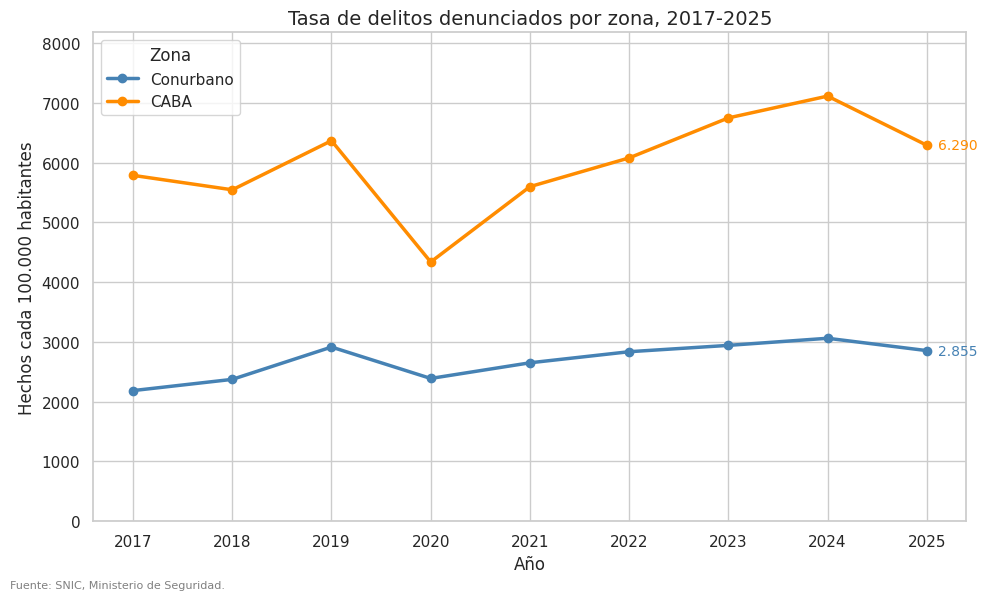

In [114]:
# Tasa total por zona y año: hechos de la zona / población de la zona * 100.000
# (usa base_zonas, la tabla de la celda A)

# 1) Población de cada comuna/partido y año, despejada de la tasa del SNIC
k = base_zonas[(base_zonas["tasa_hechos"] > 0) & (base_zonas["cantidad_hechos"] > 0)].copy()
k["pob"] = k["cantidad_hechos"] / k["tasa_hechos"] * 100000
pob = (k.groupby(["zona", "Departamentos", "Año"])["pob"].mean()   # una población por comuna/partido y año
         .groupby(["zona", "Año"]).sum())                          # se suman las comunas/partidos de cada zona

# 2) Hechos totales por zona y año
hechos_zona = base_zonas.groupby(["zona", "Año"])["cantidad_hechos"].sum()

# 3) Tasa de cada zona
tasa_zona = (hechos_zona / pob * 100000).unstack(0)

# 4) Gráfico de líneas
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(tasa_zona.index, tasa_zona["Conurbano"], marker="o", linewidth=2.5, color="steelblue", label="Conurbano")
ax.plot(tasa_zona.index, tasa_zona["CABA"], marker="o", linewidth=2.5, color="darkorange", label="CABA")
for zona, color in [("Conurbano", "steelblue"), ("CABA", "darkorange")]:
    ax.annotate(f"{tasa_zona[zona].iloc[-1]:,.0f}".replace(",", "."), (tasa_zona.index[-1], tasa_zona[zona].iloc[-1]),
                textcoords="offset points", xytext=(8, 0), color=color, fontsize=10, va="center")
ax.set_title("Tasa de delitos denunciados por zona, 2017-2025", fontsize=14)
ax.set_xlabel("Año")
ax.set_ylabel("Hechos cada 100.000 habitantes")
ax.set_xticks(tasa_zona.index)
ax.set_ylim(0, tasa_zona.max().max() * 1.15)
ax.legend(title="Zona")
fig.text(0.01, 0.005, "Fuente: SNIC, Ministerio de Seguridad.", fontsize=8, color="gray")
plt.tight_layout()
plt.savefig("tasa_total_zonas.png", dpi=150, bbox_inches="tight")
plt.show()

La tasa de delitos denunciados de CABA es más alta que la del Conurbano en todos los
años: entre 1,8 y 2,6 veces mayor. En 2024, por ejemplo, fue de 7.112 hechos cada 100.000 habitantes en CABA
y de 3.061 en el Conurbano. Las dos zonas muestran una caída en 2020 y un máximo en 2024.

Entre 2017 y 2025 la tasa creció más en el Conurbano (de 2.186 a 2.855) que en CABA (de 5.786 a 6.290), por
lo que la brecha entre las dos se achicó.

Que la tasa sea más alta en CABA no significa necesariamente que haya más delito: la tasa se calcula con la
población residente y CABA recibe mucha gente que trabaja o circula sin vivir ahí. Además, la propensión a
denunciar puede ser distinta entre zonas, y algunos tipos de delito se empiezan a registrar después de 2017,
lo que influye en el aumento. La caída de 2020 coincide con la cuarentena, pero con estos datos no podemos
afirmar que esa sea la causa.

